In [ ]:
from google.colab import files

uploaded = files.upload()

Saving password_strength_ml_dataset_3000(1).xlsx to password_strength_ml_dataset_3000(1).xlsx


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)



In [ ]:
df = pd.read_excel(
    "password_strength_ml_dataset_3000(1).xlsx",
    sheet_name="Password Dataset"
)

df.head()

,Record_ID,Password,Length,Uppercase_Count,Lowercase_Count,Digit_Count,Special_Count,Unique_Characters,Strength_Score,Strength
0,1,$yksyvmZeHI^9$8,15,3,7,2,3,13,6,Strong
1,2,b90pu$XPAcI2,12,4,4,3,1,12,6,Strong
2,3,n1n7rM$U4ukSdWAU,16,6,6,3,1,14,6,Strong
3,4,XDNC1dSl#qvh,12,5,5,1,1,12,6,Strong
4,5,Jcozhibt6,9,1,7,1,0,9,4,Medium


In [ ]:
print("Dataset shape:", df.shape)
print(df.columns)

Dataset shape: (3000, 10)
Index(['Record_ID', 'Password', 'Length', 'Uppercase_Count', 'Lowercase_Count',
       'Digit_Count', 'Special_Count', 'Unique_Characters', 'Strength_Score',
       'Strength'],
      dtype='object')


In [ ]:
features = [
    "Length",
    "Uppercase_Count",
    "Lowercase_Count",
    "Digit_Count",
    "Special_Count",
    "Unique_Characters",
    "Strength_Score"
]

X = df[features]
y = df["Strength"]

In [ ]:
print(y.value_counts())

Strength
Strong    1000
Medium    1000
Weak      1000
Name: count, dtype: int64


In [ ]:
print(y.value_counts(normalize=True) * 100)

Strength
Strong    33.333333
Medium    33.333333
Weak      33.333333
Name: proportion, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2400
Testing records: 600


In [ ]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(
    y_test, y_pred_dt, average="weighted"
)
dt_recall = recall_score(
    y_test, y_pred_dt, average="weighted"
)
dt_f1 = f1_score(
    y_test, y_pred_dt, average="weighted"
)

print("Decision Tree")
print("Accuracy :", dt_accuracy * 100, "%")
print("Precision:", dt_precision * 100, "%")
print("Recall   :", dt_recall * 100, "%")
print("F1 Score :", dt_f1 * 100, "%")

Decision Tree
Accuracy : 100.0 %
Precision: 100.0 %
Recall   : 100.0 %
F1 Score : 100.0 %


In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted"
)

rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted"
)

rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted"
)

print("Random Forest")
print("Accuracy :", rf_accuracy * 100, "%")
print("Precision:", rf_precision * 100, "%")
print("Recall   :", rf_recall * 100, "%")
print("F1 Score :", rf_f1 * 100, "%")

Random Forest
Accuracy : 100.0 %
Precision: 100.0 %
Recall   : 100.0 %
F1 Score : 100.0 %


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test, y_pred_lr, average="weighted"
)

lr_recall = recall_score(
    y_test, y_pred_lr, average="weighted"
)

lr_f1 = f1_score(
    y_test, y_pred_lr, average="weighted"
)

print("Logistic Regression")
print("Accuracy :", lr_accuracy * 100, "%")
print("Precision:", lr_precision * 100, "%")
print("Recall   :", lr_recall * 100, "%")
print("F1 Score :", lr_f1 * 100, "%")

Logistic Regression
Accuracy : 100.0 %
Precision: 100.0 %
Recall   : 100.0 %
F1 Score : 100.0 %


In [ ]:
results = pd.DataFrame({
    "Algorithm": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression"
    ],

    "Accuracy (%)": [
        dt_accuracy * 100,
        rf_accuracy * 100,
        lr_accuracy * 100
    ],

    "Precision (%)": [
        dt_precision * 100,
        rf_precision * 100,
        lr_precision * 100
    ],

    "Recall (%)": [
        dt_recall * 100,
        rf_recall * 100,
        lr_recall * 100
    ],

    "F1-Score (%)": [
        dt_f1 * 100,
        rf_f1 * 100,
        lr_f1 * 100
    ]
})

results.round(2)

,Algorithm,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Decision Tree,100.0,100.0,100.0,100.0
1,Random Forest,100.0,100.0,100.0,100.0
2,Logistic Regression,100.0,100.0,100.0,100.0


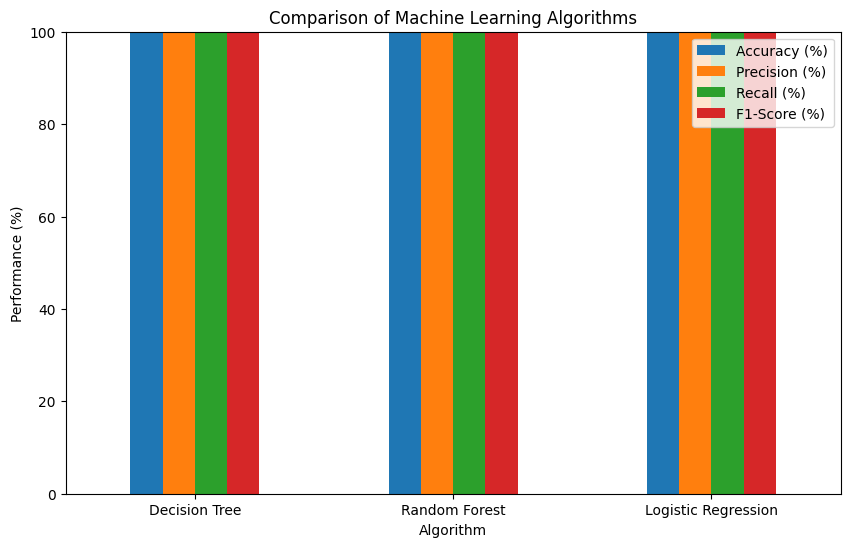

In [ ]:
import matplotlib.pyplot as plt

results.set_index("Algorithm").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Performance (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [ ]:
print("DECISION TREE")
print(classification_report(y_test, y_pred_dt))

DECISION TREE
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       200
        Weak       1.00      1.00      1.00       200

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



In [ ]:
print("RANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       200
        Weak       1.00      1.00      1.00       200

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



In [ ]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       200
        Weak       1.00      1.00      1.00       200

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



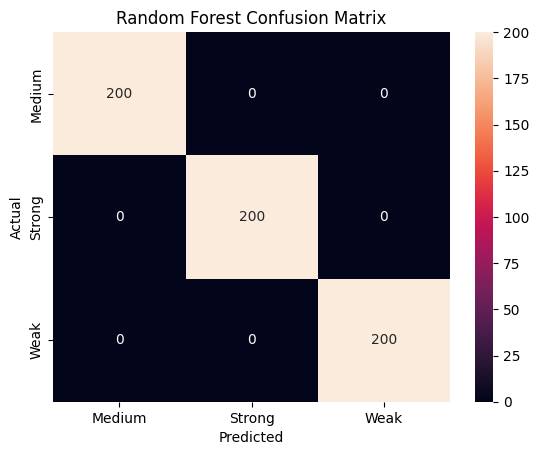

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Medium", "Strong", "Weak"],
    yticklabels=["Medium", "Strong", "Weak"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)

n_weak = 500
n_medium = 1000
n_strong = 1500

# Generate password features
def generate_passwords(n, category):
    data = []

    for i in range(n):

        if category == "Weak":
            length = np.random.randint(4, 10)
            uppercase = np.random.randint(0, 2)
            lowercase = np.random.randint(1, 4)
            digits = np.random.randint(0, 2)
            special = np.random.randint(0, 2)
            common = np.random.choice([0, 1], p=[0.2, 0.8])

        elif category == "Medium":
            length = np.random.randint(7, 14)
            uppercase = np.random.randint(0, 3)
            lowercase = np.random.randint(2, 7)
            digits = np.random.randint(1, 4)
            special = np.random.randint(0, 2)
            common = np.random.choice([0, 1], p=[0.5, 0.5])

        else:
            length = np.random.randint(10, 21)
            uppercase = np.random.randint(1, 4)
            lowercase = np.random.randint(4, 11)
            digits = np.random.randint(2, 6)
            special = np.random.randint(1, 4)
            common = np.random.choice([0, 1], p=[0.85, 0.15])

        # Add small random noise
        if np.random.random() < 0.15:
            length += np.random.randint(-2, 3)

        if np.random.random() < 0.10:
            digits = max(0, digits + np.random.randint(-1, 2))

        if np.random.random() < 0.10:
            special = max(0, special + np.random.randint(-1, 2))

        data.append([
            length,
            uppercase,
            lowercase,
            digits,
            special,
            common,
            category
        ])

    return data


weak_data = generate_passwords(n_weak, "Weak")
medium_data = generate_passwords(n_medium, "Medium")
strong_data = generate_passwords(n_strong, "Strong")

data = weak_data + medium_data + strong_data

df = pd.DataFrame(data, columns=[
    "Password_Length",
    "Uppercase_Count",
    "Lowercase_Count",
    "Digit_Count",
    "Special_Count",
    "Common_Password",
    "Strength"
])

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["Strength"].value_counts())

df.head()

Dataset shape: (3000, 7)
Strength
Strong    1500
Medium    1000
Weak       500
Name: count, dtype: int64


,Password_Length,Uppercase_Count,Lowercase_Count,Digit_Count,Special_Count,Common_Password,Strength
0,13,2,6,2,1,0,Strong
1,10,2,3,1,0,0,Medium
2,20,1,6,3,1,0,Strong
3,6,0,1,0,0,0,Weak
4,10,3,6,6,3,0,Strong


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = df.drop("Strength", axis=1)
y = df["Strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling for Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=7,
        min_samples_leaf=5,
        random_state=42
    )
}

results = []

# Logistic Regression
models["Logistic Regression"].fit(X_train_scaled, y_train)
lr_pred = models["Logistic Regression"].predict(X_test_scaled)

results.append([
    "Logistic Regression",
    accuracy_score(y_test, lr_pred),
    precision_score(y_test, lr_pred, average="weighted"),
    recall_score(y_test, lr_pred, average="weighted"),
    f1_score(y_test, lr_pred, average="weighted")
])

# Decision Tree
models["Decision Tree"].fit(X_train, y_train)
dt_pred = models["Decision Tree"].predict(X_test)

results.append([
    "Decision Tree",
    accuracy_score(y_test, dt_pred),
    precision_score(y_test, dt_pred, average="weighted"),
    recall_score(y_test, dt_pred, average="weighted"),
    f1_score(y_test, dt_pred, average="weighted")
])

# Random Forest
models["Random Forest"].fit(X_train, y_train)
rf_pred = models["Random Forest"].predict(X_test)

results.append([
    "Random Forest",
    accuracy_score(y_test, rf_pred),
    precision_score(y_test, rf_pred, average="weighted"),
    recall_score(y_test, rf_pred, average="weighted"),
    f1_score(y_test, rf_pred, average="weighted")
])

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

results_df

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.963333,0.964104,0.963333,0.963467
1,Decision Tree,0.930000,0.933462,0.930000,0.929192
2,Random Forest,0.958333,0.958484,0.958333,0.958320


In [ ]:
results_percentage = results_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2).astype(str) + "%"

results_percentage

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,96.33%,96.41%,96.33%,96.35%
1,Decision Tree,93.0%,93.35%,93.0%,92.92%
2,Random Forest,95.83%,95.85%,95.83%,95.83%


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving password_strength_ml_dataset_3000_corrected.xlsx to password_strength_ml_dataset_3000_corrected.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
df = pd.read_excel("password_strength_ml_dataset_3000_corrected.xlsx",
                   sheet_name="Password Dataset")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (3000, 10)


,Record_ID,Password,Length,Uppercase_Count,Lowercase_Count,Digit_Count,Special_Count,Unique_Characters,Strength_Score,Strength
0,1,roceqy1#,8,0,6,1,1,8,4,Medium
1,2,T3uwgI$nl6lB,12,3,6,2,1,11,6,Strong
2,3,Ykqfkmgi7,9,1,7,1,0,8,4,Medium
3,4,Pxbwqxxm3,9,1,7,1,0,7,4,Medium
4,5,fcmmxx90,8,0,6,2,0,6,3,Medium


In [ ]:
print(df["Strength"].value_counts())

Strength
Strong    1500
Medium    1000
Weak       500
Name: count, dtype: int64


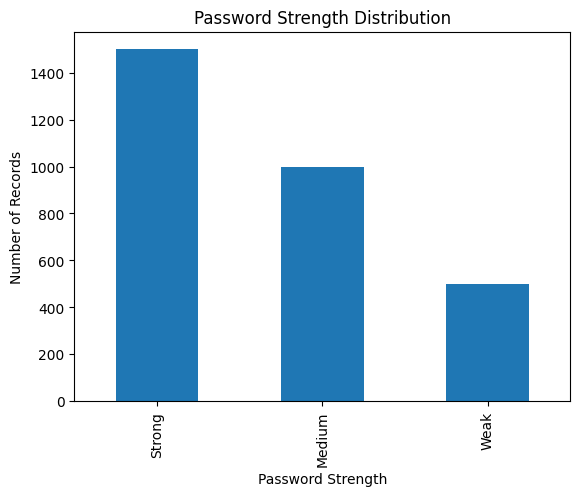

In [ ]:
df["Strength"].value_counts().plot(kind="bar")

plt.title("Password Strength Distribution")
plt.xlabel("Password Strength")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
features = [
    "Length",
    "Uppercase_Count",
    "Lowercase_Count",
    "Digit_Count",
    "Special_Count",
    "Unique_Characters"
]

X = df[features]
y = df["Strength"]

In [ ]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Classes:", encoder.classes_)

Classes: ['Medium' 'Strong' 'Weak']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2400
Testing records: 600


In [ ]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [ ]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=6
)

In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

results = []

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

results_df

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0


In [ ]:
results_percentage = results_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2)

results_percentage

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,100.0,100.0,100.0,100.0
1,Decision Tree,100.0,100.0,100.0,100.0
2,Random Forest,100.0,100.0,100.0,100.0


In [ ]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=encoder.classes_,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       300
        Weak       1.00      1.00      1.00       100

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600


Decision Tree
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       300
        Weak       1.00      1.00      1.00       100

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600


Random Forest
              precision    recall  f1-score   support

      Medium       1.00      1.00      1.00       200
      Strong       1.00      1.00      1.00       300
        Weak       1.00 

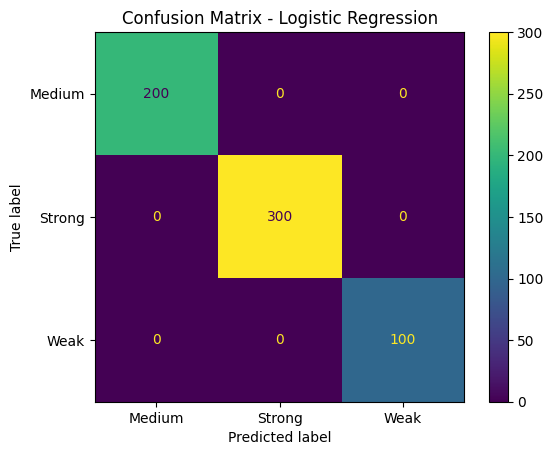

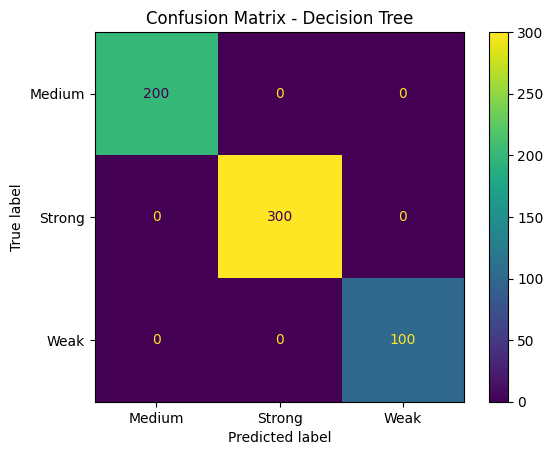

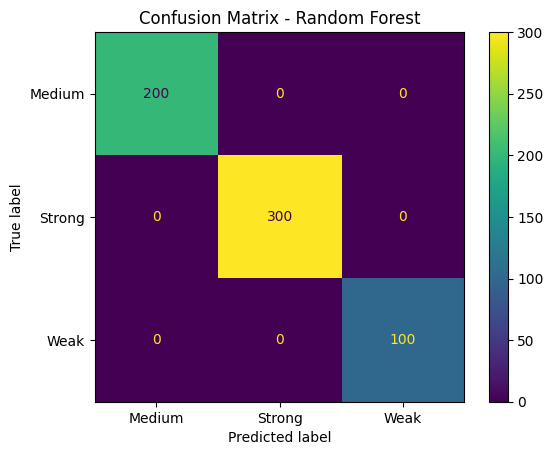

In [ ]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=encoder.classes_
    )

    disp.plot()

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

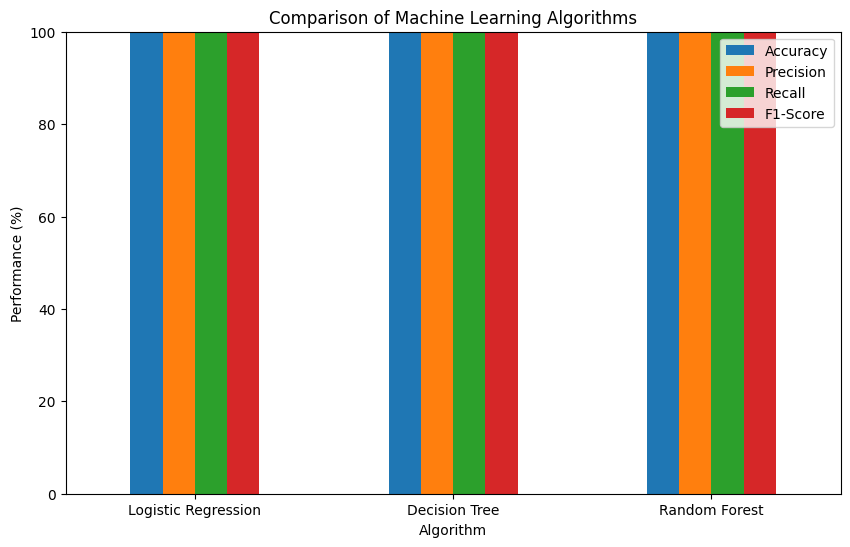

In [ ]:
results_percentage.plot(
    x="Algorithm",
    y=["Accuracy", "Precision", "Recall", "F1-Score"],
    kind="bar",
    figsize=(10,6)
)

plt.title("Comparison of Machine Learning Algorithms")
plt.ylabel("Performance (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [ ]:
best_model = results_percentage.loc[
    results_percentage["F1-Score"].idxmax()
]

print("Best Algorithm:", best_model["Algorithm"])
print("Accuracy:", best_model["Accuracy"], "%")
print("Precision:", best_model["Precision"], "%")
print("Recall:", best_model["Recall"], "%")
print("F1-Score:", best_model["F1-Score"], "%")

Best Algorithm: Logistic Regression
Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1-Score: 100.0 %


In [ ]:
rf = random_forest

importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

Length               0.431159
Unique_Characters    0.242680
Uppercase_Count      0.160262
Special_Count        0.075732
Lowercase_Count      0.056810
Digit_Count          0.033357
dtype: float64


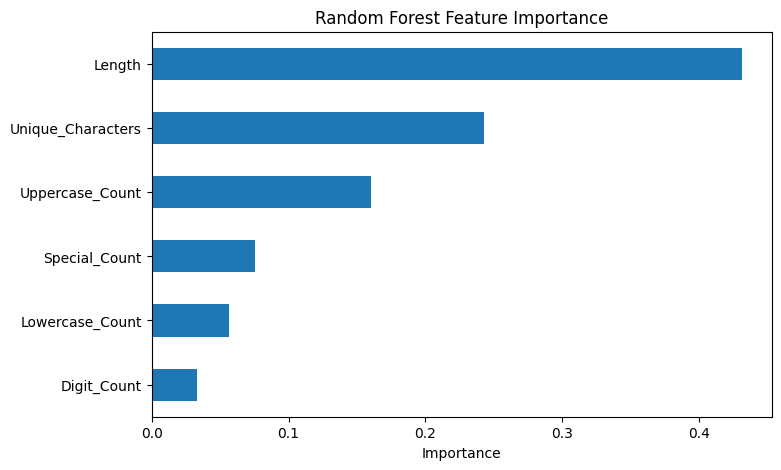

In [ ]:
importance.sort_values().plot(kind="barh", figsize=(8,5))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

In [ ]:
new_password_features = pd.DataFrame({
    "Length": [12],
    "Uppercase_Count": [2],
    "Lowercase_Count": [5],
    "Digit_Count": [3],
    "Special_Count": [2],
    "Unique_Characters": [11]
})

prediction = random_forest.predict(new_password_features)

predicted_strength = encoder.inverse_transform(prediction)

print("Predicted Password Strength:",
      predicted_strength[0])

Predicted Password Strength: Strong
